# 17 — Week 5: hybrid QNN and classical controls: checks, timing, overfit sanity, gradient variance, first validation run

Model code: `src/models/quantum.py`. All models share the protocol of every network in the benchmark (same usable
origins, 60-minute univariate window, local scaling, direct h = 1/5/15 output, masked MSE, Adam, early stopping on mean
validation MAE). Architecture: `Linear(60 -> n) -> a * tanh -> middle block -> Linear(n -> 3)`; the middle block is

* `quantum` — variational circuit, n qubits, L layers, angle embedding with data re-uploading, Rot gates, CNOT ring
  (= StronglyEntanglingLayers), `<Z>` readout; `entangle=False` = entanglement ablation;
* `mlp` — classical control `n -> k -> n` (tanh), k chosen to match the circuit's 3nL parameters;
* `bottleneck` — classical control without a trainable middle (`cos(angle)`).

Provisional design decisions (assistant as data expert): univariate input (same as PatchTST and `gru_uni`, the
references for the quantum comparison); 4 qubits x 2 layers as the main configuration (Week 6 sweeps qubits and data
fraction); trainable input scaling initialised at pi/2; exact statevector simulation (no shots, no noise). The circuits
are small enough to be simulated exactly on a laptop: **no claim of computational quantum advantage**.

Cells: 2 unit checks (no real data) · 3 dry run on synthetic data · 4 timing on real data (decision point of the plan:
> ~10 min per epoch) · 5 overfit sanity check on 1% of train · 6 gradient variance vs qubits · 7 first validation run
(seed 0) of the hybrid model, its two controls and the entanglement ablation · 8 summary · 9 export.
Every variant that is timed or trained is appended to `reports/week5/quantum_variants_log.csv`.
**The test split is not used in this notebook.**

In [1]:
# Cell 1: setup
import sys, json, time, math, shutil, warnings, traceback
from pathlib import Path
from importlib.metadata import version
import numpy as np
import polars as pl
import torch
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pennylane as qml
from models import rnn as R
from models import quantum as Q

GROUP = "week5_qnn"
REP = ROOT / "reports" / "week5"
FIG = ROOT / "reports" / "figures" / "week5"
REP.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
DATA_CFG = {"scaling": "local", "calendar": False, "covariates": False}
PROTOCOL = {"lr": 1e-3, "batch": 512, "epochs": 30, "patience": 3, "grad_clip": 1.0, "weight_decay": 0.0,
            "scaling": "local", "calendar": False, "covariates": False, "backend": "default.qubit",
            "dataset": "data/processed/model_dataset.parquet", "dataset_meta": "data/processed/model_dataset_meta.json"}
MAIN = {"n_qubits": 4, "n_layers": 2, "reupload": True, "entangle": True}
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]     # categorical slots 1-4 (fixed order)
SUMMARY = {}
print("pennylane", qml.__version__, "| lightning", version("pennylane_lightning"), "| torch", torch.__version__,
      "| threads", torch.get_num_threads())

pennylane 0.45.1 | lightning 0.45.0 | torch 2.14.1 | threads 4


In [2]:
# Cell 2: unit checks of the circuit code (no real data)
checks = {}
torch.manual_seed(0)
a = (torch.rand(6, 4) * 2 - 1) * 1.5

# (a) default.qubit (backprop, broadcasting) and lightning.qubit (adjoint) give the same outputs and gradients
for ent in (True, False):
    qd = Q.QuantumBlock(4, 2, entangle=ent, backend="default.qubit")
    ql = Q.QuantumBlock(4, 2, entangle=ent, backend="lightning.qubit")
    ql.weights.data = qd.weights.data.clone()
    od, ol = qd(a), ql(a)
    od.sum().backward(); ol.sum().backward()
    d_out = float((od - ol).abs().max()); d_grad = float((qd.weights.grad - ql.weights.grad).abs().max())
    checks[f"backends_agree_entangle_{ent}"] = d_out < 1e-5 and d_grad < 1e-5
    print(f"(a) entangle={ent}: max |out diff| {d_out:.1e} | max |grad diff| {d_grad:.1e}")

# (b) our layer equals PennyLane's StronglyEntanglingLayers (embedding once, 3 layers)
qb = Q.QuantumBlock(4, 3, reupload=False, entangle=True)
dev = qml.device("default.qubit", wires=4)
@qml.qnode(dev, interface="torch")
def ref(x, w):
    qml.AngleEmbedding(x, wires=range(4))
    qml.StronglyEntanglingLayers(w, wires=range(4))
    return [qml.expval(qml.PauliZ(i)) for i in range(4)]
d_sel = float((qb(a) - torch.stack(list(ref(a, qb.weights)), -1).float()).abs().max())
checks["equals_StronglyEntanglingLayers"] = d_sel < 1e-5
print(f"(b) vs qml.StronglyEntanglingLayers: max |diff| {d_sel:.1e}")

# (c) entanglement ablation is a product state: changing the angle of qubit 0 changes <Z_0> only
qn = Q.QuantumBlock(4, 2, entangle=False)
qe = Q.QuantumBlock(4, 2, entangle=True); qe.weights.data = qn.weights.data.clone()
b = a.clone(); b[:, 0] += 0.9
ch_n = (qn(a) - qn(b)).abs().max(0).values.detach().numpy()
ch_e = (qe(a) - qe(b)).abs().max(0).values.detach().numpy()
checks["no_entanglement_is_product_state"] = bool(ch_n[0] > 1e-3 and ch_n[1:].max() < 1e-6 and ch_e[1:].max() > 1e-3)
print(f"(c) change of <Z_i> when only angle 0 changes | no entanglement: {np.round(ch_n, 4)} | entangled: {np.round(ch_e, 4)}")

# (d) parameter counts of the hybrid model and its controls
rows = []
for nq, L in [(2, 2), (4, 2), (4, 4), (6, 2), (8, 2), (8, 4)]:
    for mid in ("quantum", "mlp", "bottleneck"):
        _, p = Q.build({"n_qubits": nq, "n_layers": L, "middle": mid}, R.INPUT_LEN)
        rows.append({"n_qubits": nq, "n_layers": L, "middle": mid, **p})
pc = pl.DataFrame(rows)
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(200)
print("(d) parameter counts (input 60 minutes):"); print(pc)
mm = pc.filter(pl.col("middle") != "bottleneck").pivot(on="middle", index=["n_qubits", "n_layers"], values="n_params_middle")
checks["control_matched_within_15pct"] = bool(((mm["mlp"] - mm["quantum"]).abs() / mm["quantum"] <= 0.15).all())
SUMMARY["param_counts"] = rows
UNIT_OK = all(checks.values())
print("\n", checks, "\nUNIT CHECKS PASSED" if UNIT_OK else "\nUNIT CHECKS FAILED: send this output")

(a) entangle=True: max |out diff| 1.2e-07 | max |grad diff| 2.4e-07
(a) entangle=False: max |out diff| 3.6e-07 | max |grad diff| 9.5e-07
(b) vs qml.StronglyEntanglingLayers: max |diff| 0.0e+00
(c) change of <Z_i> when only angle 0 changes | no entanglement: [1.3962 0.     0.     0.    ] | entangled: [0.1378 0.1362 0.0507 0.1256]
(d) parameter counts (input 60 minutes):
shape: (18, 7)
┌──────────┬──────────┬────────────┬──────────┬──────────────────┬─────────────────┬──────────────────┐
│ n_qubits ┆ n_layers ┆ middle     ┆ n_params ┆ n_params_encoder ┆ n_params_middle ┆ n_params_decoder │
│ ---      ┆ ---      ┆ ---        ┆ ---      ┆ ---              ┆ ---             ┆ ---              │
│ i64      ┆ i64      ┆ str        ┆ i64      ┆ i64              ┆ i64             ┆ i64              │
╞══════════╪══════════╪════════════╪══════════╪══════════════════╪═════════════════╪══════════════════╡
│ 2        ┆ 2        ┆ quantum    ┆ 145      ┆ 124              ┆ 12              ┆ 9       

In [3]:
# Cell 3: DRY RUN of the whole pipeline on SYNTHETIC data (2 epochs, 5,000 samples, no tracking; deleted afterwards)
def synth(n=30000, seed=0):
    rng = np.random.default_rng(seed)
    t = np.arange(n)
    x = np.zeros(n)
    e = rng.normal(0, 0.4, n)
    for i in range(1, n):
        x[i] = 0.9 * x[i - 1] + e[i]
    P = 30 + np.cumsum(rng.normal(0, 0.01, n)) + x - 0.3 * (t % 5 == 0)
    valid = np.ones(n, bool)
    for g0 in rng.choice(np.arange(500, n - 500), 6, replace=False):
        valid[g0:g0 + 150] = False
    i_tr, i_va = int(0.7 * n), int(0.85 * n)
    split = np.where(t < i_tr, "train", np.where(t < i_va, "val", "test"))
    c = np.concatenate([[0], np.cumsum(~valid)])
    win_ok = np.zeros(n, bool)
    win_ok[R.INPUT_LEN - 1:] = (c[R.INPUT_LEN:] - c[:n - R.INPUT_LEN + 1]) == 0
    Pv = np.where(valid, P, np.nan)
    L24 = pl.Series(Pv).fill_nan(None).rolling_mean(1440, min_samples=720).to_numpy()
    cols = {"minute_epoch": t * 60, "P_kW": Pv, "valid": valid, "split": split, "mod5": (t % 5).astype(np.int64),
            "hour_sin": np.sin(2 * np.pi * (t // 60 % 24) / 24), "hour_cos": np.cos(2 * np.pi * (t // 60 % 24) / 24),
            "L24_kW": L24}
    thr = {}
    for h in R.HORIZONS:
        ok = win_ok.copy()
        ok[n - h:] = False
        ok[:n - h] &= valid[h:]
        sp = np.full(n, None, dtype=object)
        tt = np.arange(n - h)
        sp[:n - h] = np.where(tt + h < i_tr, "train", np.where((tt >= i_tr) & (tt + h < i_va), "val",
                              np.where(tt >= i_va, "test", None)))
        ok &= sp != None  # noqa: E711
        rel = np.full(n, np.nan)
        rel[:n - h] = np.abs(P[h:] - P[:n - h]) / L24[:n - h]
        trm = ok & (sp == "train") & np.isfinite(rel)
        thr[str(h)] = {"rel_p95": float(np.quantile(rel[trm], 0.95))}
        ramp = np.where(ok & np.isfinite(rel), (rel > thr[str(h)]["rel_p95"]).astype(float), np.nan)
        cols[f"ok_h{h}"], cols[f"split_h{h}"], cols[f"ramp_h{h}"] = ok, sp.tolist(), ramp
    df = pl.DataFrame(cols).with_columns(pl.col("P_kW").fill_nan(None), pl.col("L24_kW").fill_nan(None))
    return df, {"thresholds": thr}

assert UNIT_OK, "run cell 2 first and make sure the unit checks passed"
DRY = "_dryrun_week5"
sm, smeta = synth()
sdata = R.Data(sm, DATA_CFG)
dry_ok = True
try:
    for mid in ("quantum", "mlp", "bottleneck"):
        cfg = {**PROTOCOL, **MAIN, "middle": mid, "seed": 0, "epochs": 2, "max_train_samples": 5000}
        res = Q.run_and_score(ROOT, sm, smeta, sdata, cfg, DRY, tracking_mode="disabled", log=lambda s: None)
        out = ROOT / "experiments" / DRY / f"{Q.variant_name(cfg)}_s0"
        files = ["config.yaml", "history.csv", "model.pt", "predictions_val.parquet", "metrics.json"]
        missing = [f for f in files if not (out / f).exists()]
        pr = pl.read_parquet(out / "predictions_val.parquet")
        finite = all(np.isfinite(r_["MAE"]) and np.isfinite(r_["skill_MAE"]) for r_ in res["val"])
        good = not missing and finite and pr.height > 0 and pr["yhat"].is_finite().all()
        dry_ok &= bool(good)
        print(f"{Q.variant_name(cfg):24s} files ok: {not missing} | prediction rows {pr.height:,} | metrics finite: "
              f"{finite} | params {res['info']['n_params']} | skill h1/h5/h15: " +
              " / ".join(f"{r_['skill_MAE']:+.3f}" for r_ in res["val"]))
except Exception:
    dry_ok = False
    traceback.print_exc()
finally:
    shutil.rmtree(ROOT / "experiments" / DRY, ignore_errors=True)
    shutil.rmtree(ROOT / "experiments" / "runs" / DRY, ignore_errors=True)
    log_p = REP / "quantum_variants_log.csv"            # remove dry-run rows from the variant log
    if log_p.exists():
        lg = pl.read_csv(log_p, infer_schema_length=0)
        lg = lg.filter(pl.col("group") != DRY) if "group" in lg.columns else lg
        lg.write_csv(log_p) if lg.height else log_p.unlink()
print("\nDRY RUN PASSED (pipeline works end to end; skills after 2 epochs on synthetic data are not meaningful)"
      if dry_ok else "\nDRY RUN FAILED: do not run the next cells, send this output")

hqnn_q4_l2               files ok: True | prediction rows 12,831 | metrics finite: True | params 287 | skill h1/h5/h15: +0.004 / -0.004 / -0.005
ctrl_mlp_q4_l2           files ok: True | prediction rows 12,831 | metrics finite: True | params 285 | skill h1/h5/h15: -0.034 / +0.032 / +0.047
ctrl_bottleneck_q4_l2    files ok: True | prediction rows 12,831 | metrics finite: True | params 263 | skill h1/h5/h15: -0.080 / -0.001 / -0.002

DRY RUN PASSED (pipeline works end to end; skills after 2 epochs on synthetic data are not meaningful)


In [4]:
# Cell 4: TIMING on real data (train split only; nothing is scored). Decision point of the plan: an epoch > ~10 min.
assert dry_ok, "run cell 3 first"
md = pl.read_parquet(ROOT / PROTOCOL["dataset"])
meta = json.loads((ROOT / PROTOCOL["dataset_meta"]).read_text())
data = R.Data(md, DATA_CFG)
n_tr, n_va = len(data.origins("train")), len(data.origins("val"))
print(f"rows {md.height:,} | train origins {n_tr:,} | val origins {n_va:,}")

tim = []
r = Q.time_steps({**MAIN, "backend": "lightning.qubit"}, data, n_batches=2, bs=64, n_pred=256)
tim.append(r)
for nq in (2, 4, 6, 8):
    for L in (2, 4):
        tim.append(Q.time_steps({"n_qubits": nq, "n_layers": L, "backend": "default.qubit"}, data, n_batches=10, bs=512))
for mid in ("mlp", "bottleneck"):
    tim.append(Q.time_steps({**MAIN, "middle": mid}, data, n_batches=10, bs=512))
tim = pl.DataFrame(tim).with_columns(pl.col("ms_per_train_sample").round(4), pl.col("ms_per_pred_sample").round(4),
                                    pl.col("est_epoch_min_full").round(2))
print(tim.select("variant", "backend", "n_params", "n_params_middle", "ms_per_train_sample", "ms_per_pred_sample",
                 "est_epoch_min_full"))
tim.write_csv(REP / "qnn_timing.csv")
for row in tim.to_dicts():
    Q.log_variant(ROOT, {"stage": "timing", "group": GROUP, **{k: row[k] for k in
                  ("variant", "backend", "n_params", "n_params_middle", "est_epoch_min_full")}})

dq = tim.filter(pl.col("backend") == "default.qubit")
speedup = float(tim.filter(pl.col("backend") == "lightning.qubit")["ms_per_train_sample"][0] /
                dq.filter(pl.col("variant") == "hqnn_q4_l2")["ms_per_train_sample"][0])
worst = float(dq.filter(pl.col("variant").str.starts_with("hqnn"))["est_epoch_min_full"].max())
BACKEND = "default.qubit"
MAX_TRAIN = None if worst <= 10 else int(n_tr * 10 / worst)
SUMMARY["timing"] = {"speedup_default_vs_lightning": speedup, "worst_epoch_min_full_train": worst,
                     "backend": BACKEND, "max_train_samples": MAX_TRAIN}
print(f"\ndefault.qubit (backprop, broadcasting) is {speedup:.0f}x faster than lightning.qubit (adjoint) per sample; "
      "both exact and equal to 1e-5 (cell 2)")
print(f"slowest hybrid in the grid (8 qubits, 4 layers): about {worst:.1f} min per epoch on the full train split")
print(f"DECISION (provisional): backend {BACKEND}; " +
      ("full train split, no subsample (every epoch <= 10 min)" if MAX_TRAIN is None
       else f"subsample of {MAX_TRAIN:,} train origins to keep an epoch under 10 min"))

rows 303,840 | train origins 196,700 | val origins 42,575
shape: (11, 7)
┌───────────────────────┬─────────────────┬──────────┬─────────────────┬─────────────────────┬────────────────────┬────────────────────┐
│ variant               ┆ backend         ┆ n_params ┆ n_params_middle ┆ ms_per_train_sample ┆ ms_per_pred_sample ┆ est_epoch_min_full │
│ ---                   ┆ ---             ┆ ---      ┆ ---             ┆ ---                 ┆ ---                ┆ ---                │
│ str                   ┆ str             ┆ i64      ┆ i64             ┆ f64                 ┆ f64                ┆ f64                │
╞═══════════════════════╪═════════════════╪══════════╪═════════════════╪═════════════════════╪════════════════════╪════════════════════╡
│ hqnn_q4_l2            ┆ lightning.qubit ┆ 287      ┆ 24              ┆ 3.1266              ┆ 1.8612             ┆ 11.57              │
│ hqnn_q2_l2            ┆ default.qubit   ┆ 145      ┆ 12              ┆ 0.012               ┆ 0.0012    

In [5]:
# Cell 5: OVERFIT SANITY CHECK on 1% of the train origins (plan item). Not the protocol: lr 1e-2, batch 64, 60 epochs,
# no early stopping; "validation" = the same 1% (so the score is a TRAINING score). A healthy pipeline must fit it.
sub = Q.subsample(data.origins("train"), int(round(0.01 * n_tr)), seed=0)
p_sub = []
for h in R.HORIZONS:
    t = sub[np.isin(sub, data.idx[h]["train"])]
    p_sub.append(float(np.mean(np.abs(data.P[t + h] - data.P[t]))))
ofit = []
for mid in ("quantum", "mlp", "bottleneck"):
    cfg = {**PROTOCOL, **MAIN, "middle": mid, "seed": 0, "lr": 1e-2, "batch": 64, "epochs": 60, "patience": 60,
           "val_split": "train"}
    t0 = time.time()
    m, d, hist, info = Q.train(md, cfg, log=lambda s: None, data=data, train_origins=sub, val_origins=sub)
    last = hist[-1]
    sk = [1 - last[f"val_MAE_h{h}"] / p for h, p in zip(R.HORIZONS, p_sub)]
    ok = last["train_loss"] < 0.8 * hist[0]["train_loss"] and min(sk) > 0
    ofit.append({"variant": info["variant"], "n_params": info["n_params"], "n_samples": len(sub),
                 "loss_epoch1": round(hist[0]["train_loss"], 4), "loss_last": round(last["train_loss"], 4),
                 **{f"train_skill_h{h}": round(s, 3) for h, s in zip(R.HORIZONS, sk)}, "s": round(time.time() - t0, 1),
                 "check": "PASS" if ok else "CHECK"})
    Q.log_variant(ROOT, {"stage": "overfit_1pct", "group": GROUP, "variant": info["variant"],
                         "n_params": info["n_params"], **{k: v for k, v in ofit[-1].items() if k.startswith("train_skill")}})
ofit = pl.DataFrame(ofit)
print(f"1% subsample: {len(sub):,} train origins | persistence MAE on it: " + " / ".join(f"{p:.4f}" for p in p_sub) + " kW")
print(ofit)
print("\nPASS = training loss fell by >= 20% and the TRAINING skill vs persistence is positive at every horizon "
      "(a check that the pipeline can learn, not a performance result)")
SUMMARY["overfit_1pct"] = ofit.to_dicts()

1% subsample: 1,967 train origins | persistence MAE on it: 0.2689 / 0.3622 / 0.4783 kW
shape: (3, 10)
┌───────────────────────┬──────────┬───────────┬─────────────┬───┬────────────────┬─────────────────┬──────┬───────┐
│ variant               ┆ n_params ┆ n_samples ┆ loss_epoch1 ┆ … ┆ train_skill_h5 ┆ train_skill_h15 ┆ s    ┆ check │
│ ---                   ┆ ---      ┆ ---       ┆ ---         ┆   ┆ ---            ┆ ---             ┆ ---  ┆ ---   │
│ str                   ┆ i64      ┆ i64       ┆ f64         ┆   ┆ f64            ┆ f64             ┆ f64  ┆ str   │
╞═══════════════════════╪══════════╪═══════════╪═════════════╪═══╪════════════════╪═════════════════╪══════╪═══════╡
│ hqnn_q4_l2            ┆ 287      ┆ 1967      ┆ 2.0817      ┆ … ┆ 0.104          ┆ 0.078           ┆ 16.7 ┆ CHECK │
│ ctrl_mlp_q4_l2        ┆ 285      ┆ 1967      ┆ 2.0054      ┆ … ┆ 0.117          ┆ 0.088           ┆ 1.1  ┆ CHECK │
│ ctrl_bottleneck_q4_l2 ┆ 263      ┆ 1967      ┆ 2.087       ┆ … ┆ 0.027       

shape: (12, 6)
┌──────────────────┬──────────┬──────────┬──────────┬─────────────────┬──────────────────┐
│ variant          ┆ n_qubits ┆ n_layers ┆ entangle ┆ var_grad_middle ┆ var_grad_encoder │
│ ---              ┆ ---      ┆ ---      ┆ ---      ┆ ---             ┆ ---              │
│ str              ┆ i64      ┆ i64      ┆ bool     ┆ str             ┆ str              │
╞══════════════════╪══════════╪══════════╪══════════╪═════════════════╪══════════════════╡
│ hqnn_q2_l2       ┆ 2        ┆ 2        ┆ true     ┆ 1.84e-03        ┆ 5.22e-03         │
│ hqnn_q4_l2       ┆ 4        ┆ 2        ┆ true     ┆ 1.65e-04        ┆ 5.18e-04         │
│ hqnn_q6_l2       ┆ 6        ┆ 2        ┆ true     ┆ 7.42e-05        ┆ 3.25e-04         │
│ hqnn_q8_l2       ┆ 8        ┆ 2        ┆ true     ┆ 7.03e-06        ┆ 3.85e-05         │
│ hqnn_q2_l4       ┆ 2        ┆ 4        ┆ true     ┆ 2.50e-03        ┆ 9.03e-03         │
│ hqnn_noent_q2_l4 ┆ 2        ┆ 4        ┆ false    ┆ 4.76e-03        ┆ 7.9

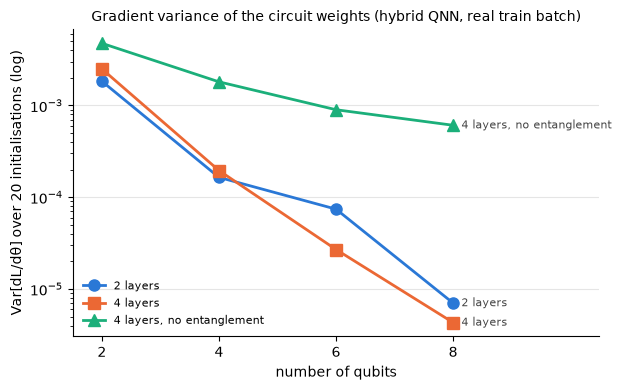

fitted log10 slope per added qubit: {'2 layers': -0.38, '4 layers': -0.458, '4 layers, no entanglement': -0.149}


In [6]:
# Cell 6: GRADIENT VARIANCE vs number of qubits (barren-plateau diagnostic; McClean et al. 2018, Cerezo et al. 2025).
# Variance over 20 random initialisations of d loss / d theta (circuit weights) on one fixed batch of 256 real train
# samples; also for the encoder weights (the gradient reaching the encoder passes through the circuit).
gv = []
for L in (2, 4):
    for nq in (2, 4, 6, 8):
        for ent in ((True, False) if L == 4 else (True,)):
            r = Q.grad_variance({"n_qubits": nq, "n_layers": L, "entangle": ent}, data, n_init=20, bs=256)
            gv.append({"n_qubits": nq, "n_layers": L, "entangle": ent, **r})
gv = pl.DataFrame(gv)
print(gv.select("variant", "n_qubits", "n_layers", "entangle", pl.col("var_grad_middle").map_elements(lambda v: f"{v:.2e}", return_dtype=pl.String),
                pl.col("var_grad_encoder").map_elements(lambda v: f"{v:.2e}", return_dtype=pl.String)))
gv.write_csv(REP / "qnn_grad_variance.csv")

fig, ax = plt.subplots(figsize=(6.4, 4.0))
series = [((2, True), "2 layers"), ((4, True), "4 layers"), ((4, False), "4 layers, no entanglement")]
markers = ["o", "s", "^"]
for (key, lab), col, mk in zip(series, COLORS, markers):
    s = gv.filter((pl.col("n_layers") == key[0]) & (pl.col("entangle") == key[1])).sort("n_qubits")
    ax.plot(s["n_qubits"], s["var_grad_middle"], color=col, lw=2, marker=mk, ms=8, label=lab)
    ax.annotate(lab, (s["n_qubits"][-1], s["var_grad_middle"][-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color="#444444")
ax.set_yscale("log")
ax.set_xticks([2, 4, 6, 8])
ax.set_xlim(1.5, 10.5)
ax.set_xlabel("number of qubits")
ax.set_ylabel("Var[dL/dθ] over 20 initialisations (log)")
ax.set_title("Gradient variance of the circuit weights (hybrid QNN, real train batch)", fontsize=10)
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
for sp_ in ("top", "right"):
    ax.spines[sp_].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "01_grad_variance.png", dpi=150)
plt.show()
slope = {}
for (key, lab) in series:
    s = gv.filter((pl.col("n_layers") == key[0]) & (pl.col("entangle") == key[1])).sort("n_qubits")
    slope[lab] = float(np.polyfit(s["n_qubits"].to_numpy(), np.log10(s["var_grad_middle"].to_numpy()), 1)[0])
print("fitted log10 slope per added qubit:", {k: round(v, 3) for k, v in slope.items()})
SUMMARY["grad_variance"] = {"table": gv.to_dicts(), "log10_slope_per_qubit": slope}

In [7]:
# Cell 7: FIRST VALIDATION RUN (seed 0, full protocol: Adam 1e-3, batch 512, patience 3, cap 30 epochs, CPU).
# Hybrid QNN 4 qubits x 2 layers, its two classical controls, and the entanglement ablation. Resumable.
# Expected time: about 5-20 min in total. W&B mode "auto". Seeds 1 and 2 and the sweeps follow in notebook 18.
VARIANTS = [{"middle": "quantum"}, {"middle": "mlp"}, {"middle": "bottleneck"}, {"middle": "quantum", "entangle": False}]
T = time.time()
first = {}
for v in VARIANTS:
    cfg = {**PROTOCOL, **MAIN, **v, "seed": 0, "backend": BACKEND}
    if MAX_TRAIN:
        cfg["max_train_samples"] = MAX_TRAIN
    try:
        first[Q.variant_name(cfg)] = Q.run_and_score(ROOT, md, meta, data, cfg, GROUP, tracking_mode="auto")
    except Exception:
        print(f"!!! {Q.variant_name(cfg)} failed:")
        traceback.print_exc(limit=5)
print(f"\nall runs handled in {(time.time() - T) / 60:.1f} min")

REF = {"lightgbm": (0.131, 0.085, 0.065), "patchtst": (0.112, 0.072, 0.059), "gru_uni": (0.058, 0.066, 0.054),
       "dlinear": (0.065, 0.030, 0.030)}          # validation skill, mean of 3 seeds (Week 4 benchmark)
try:
    b = pl.read_csv(ROOT / "reports" / "week4" / "benchmark_val_week4_all.csv")
    REF = {m: tuple(float(b.filter((pl.col("model") == m) & (pl.col("h") == h))["skill_MAE"][0]) for h in R.HORIZONS)
           for m in REF}
    print("references read from reports/week4/benchmark_val_week4_all.csv")
except Exception as e:  # noqa: BLE001
    print("references from the Week 4 handoff (csv not readable:", type(e).__name__, ")")
rows = []
for name, res in first.items():
    rows.append({"model": name, "seed": 0, "n_params": res["info"]["n_params"],
                 "n_params_middle": res["info"]["n_params_middle"],
                 **{f"skill_h{r_['h']}": round(r_["skill_MAE"], 4) for r_ in res["val"]},
                 **{f"MAE_h{r_['h']}": round(r_["MAE"], 4) for r_ in res["val"]},
                 "best_epoch": res["info"]["best_epoch"], "train_s": round(res["info"]["train_s"], 0)})
for m, s in REF.items():
    rows.append({"model": f"[ref] {m} (3 seeds)", "seed": None, "n_params": None, "n_params_middle": None,
                 **{f"skill_h{h}": v for h, v in zip(R.HORIZONS, s)}})
tab = pl.DataFrame(rows, infer_schema_length=None)
print(tab.select("model", "n_params", "n_params_middle", "skill_h1", "skill_h5", "skill_h15", "MAE_h1", "MAE_h5",
                 "MAE_h15", "best_epoch", "train_s"))
tab.write_csv(REP / "qnn_first_val_s0.csv")
SUMMARY["first_val_s0"] = tab.to_dicts()

[14:24:06] hqnn_q4_l2_s0: training
  epoch   1 | train loss 2.16810 | val MAE 0.2782 / 0.4265 / 0.5958 kW | epoch 5 s
  epoch   2 | train loss 2.06198 | val MAE 0.2742 / 0.4199 / 0.5916 kW | epoch 5 s
  epoch   3 | train loss 2.03006 | val MAE 0.2768 / 0.4195 / 0.5903 kW | epoch 6 s
  epoch   4 | train loss 2.01298 | val MAE 0.2749 / 0.4142 / 0.5870 kW | epoch 5 s
  epoch   5 | train loss 2.00110 | val MAE 0.2756 / 0.4129 / 0.5865 kW | epoch 5 s
  epoch   6 | train loss 1.99219 | val MAE 0.2800 / 0.4167 / 0.5899 kW | epoch 6 s
  epoch   7 | train loss 1.98471 | val MAE 0.2800 / 0.4144 / 0.5877 kW | epoch 6 s
  epoch   8 | train loss 1.97972 | val MAE 0.2745 / 0.4097 / 0.5834 kW | epoch 6 s
  epoch   9 | train loss 1.97648 | val MAE 0.2786 / 0.4121 / 0.5855 kW | epoch 7 s
  epoch  10 | train loss 1.97362 | val MAE 0.2745 / 0.4079 / 0.5821 kW | epoch 4 s
  epoch  11 | train loss 1.97004 | val MAE 0.2751 / 0.4081 / 0.5818 kW | epoch 5 s
  epoch  12 | train loss 1.96678 | val MAE 0.2753 / 

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/aryaneuse/.netrc.


[14:25:35] hqnn_q4_l2_s0: params 287 (middle 24) | train 69 s | best epoch 10/13 | val MAE 0.2745 / 0.4079 / 0.5821 kW | skill +0.042 / +0.051 / +0.038
[14:25:35] ctrl_mlp_q4_l2_s0: training
  epoch   1 | train loss 2.09402 | val MAE 0.2769 / 0.4183 / 0.5924 kW | epoch 0 s
  epoch   2 | train loss 2.01940 | val MAE 0.2763 / 0.4148 / 0.5883 kW | epoch 0 s
  epoch   3 | train loss 1.99833 | val MAE 0.2811 / 0.4179 / 0.5921 kW | epoch 0 s
  epoch   4 | train loss 1.98643 | val MAE 0.2786 / 0.4136 / 0.5879 kW | epoch 0 s
  epoch   5 | train loss 1.98112 | val MAE 0.2780 / 0.4121 / 0.5859 kW | epoch 0 s
  epoch   6 | train loss 1.97394 | val MAE 0.2847 / 0.4186 / 0.5942 kW | epoch 0 s
  epoch   7 | train loss 1.96788 | val MAE 0.2820 / 0.4136 / 0.5878 kW | epoch 0 s
  epoch   8 | train loss 1.96311 | val MAE 0.2757 / 0.4087 / 0.5819 kW | epoch 0 s
  epoch   9 | train loss 1.95665 | val MAE 0.2781 / 0.4099 / 0.5822 kW | epoch 0 s
  epoch  10 | train loss 1.95266 | val MAE 0.2774 / 0.4091 / 0

In [8]:
# Cell 8: summary
SUMMARY["unit_checks"] = checks
SUMMARY["protocol"] = PROTOCOL
SUMMARY["main_config"] = MAIN
SUMMARY["versions"] = {"pennylane": qml.__version__, "pennylane_lightning": version("pennylane_lightning"),
                       "torch": torch.__version__}
(REP / "qnn_smoke.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
print("written:", sorted(p.name for p in REP.iterdir()), "| figure:", FIG / "01_grad_variance.png")

written: ['qnn_first_val_s0.csv', 'qnn_grad_variance.csv', 'qnn_smoke.json', 'qnn_timing.csv', 'quantum_variants_log.csv'] | figure: /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/reports/figures/week5/01_grad_variance.png


In [9]:
# Cell 9: export outputs (save the notebook first with Cmd+S, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 17_week5_qnn_smoke.ipynb

written 17_week5_qnn_smoke_outputs.md | code cells 9 | figures 1 in 17_week5_qnn_smoke_outputs_figures
